The Concepts walkthrough stopped at plain gradient descent:

$$w \leftarrow w - \eta\,\nabla\mathcal{L}$$

Almost nobody uses that. Every training script reaches for `Adam`, and most people who
type it could not say what it does. This notebook builds up to it in four steps, each one
fixing a specific failure of the one before, with every update computed by hand.

| Optimiser | What it adds | The problem it fixes |
|---|---|---|
| SGD | &mdash; | &mdash; |
| **Momentum** | a velocity term | zig-zagging in narrow valleys |
| **RMSProp** | per-parameter step sizes | parameters on wildly different scales |
| **Adam** | both, plus bias correction | both, plus a bad start |

The point to hold onto: **all four use the identical gradient.** They differ only in what
they do with it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. A Loss Surface That Breaks Plain SGD

The classic hard case is a **narrow valley** &mdash; steep in one direction, nearly flat in
another:

$$\mathcal{L}(w_1, w_2) = \tfrac{1}{2}\big(a\,w_1^2 + b\,w_2^2\big), \qquad a \gg b$$

The gradient is dominated by the steep direction, so descent bounces across the valley
while barely advancing along it. The severity is captured by the **condition number**
$\kappa = a/b$: gradient descent needs roughly $O(\kappa)$ steps.

In [2]:
A_CURV, B_CURV = 20.0, 1.0          # steep in w1, shallow in w2

def loss(w):
    return 0.5*(A_CURV*w[0]**2 + B_CURV*w[1]**2)

def grad(w):
    return np.array([A_CURV*w[0], B_CURV*w[1]])

W_START = np.array([-1.0, -4.0])

print(f"loss(w1, w2) = 0.5 * ({A_CURV}*w1^2 + {B_CURV}*w2^2)")
print(f"minimum at (0, 0), where the loss is 0\n")
print(f"curvature along w1 : {A_CURV}")
print(f"curvature along w2 : {B_CURV}")
print(f"condition number   : {A_CURV/B_CURV:.0f}\n")
print(f"stability limit for plain SGD: eta < 2/{A_CURV} = {2/A_CURV:.4f}")
print(f"   -> the STEEP direction caps the step size, but the SHALLOW direction")
print(f"      is the one that needs large steps. That conflict is the problem.\n")

w = W_START.copy()
print(f"starting at w = {w}, loss = {loss(w):.4f}\n")
print(f"{'step':>5}  {'w1':>10}  {'w2':>10}  {'grad w1':>10}  {'grad w2':>10}  {'loss':>10}")
print("-" * 62)
ETA0 = 0.09
for k in range(6):
    g = grad(w)
    print(f"{k:>5}  {w[0]:>10.6f}  {w[1]:>10.6f}  {g[0]:>10.4f}  {g[1]:>10.4f}  "
          f"{loss(w):>10.6f}")
    w = w - ETA0*g
print("-" * 62)
print(f"\nlook at w1: it flips sign every single step - the classic zig-zag.")
print(f"   the gradient in w1 is {A_CURV/B_CURV:.0f}x larger than in w2, so w1 overshoots")
print(f"   while w2 creeps.")
print(f"\nafter 6 steps: w2 has moved from {W_START[1]:.1f} to {w[1]:.4f} - barely")
print(f"{abs(w[1]-W_START[1])/abs(W_START[1]):.1%} of the way.")

loss(w1, w2) = 0.5 * (20.0*w1^2 + 1.0*w2^2)
minimum at (0, 0), where the loss is 0

curvature along w1 : 20.0
curvature along w2 : 1.0
condition number   : 20

stability limit for plain SGD: eta < 2/20.0 = 0.1000
   -> the STEEP direction caps the step size, but the SHALLOW direction
      is the one that needs large steps. That conflict is the problem.

starting at w = [-1. -4.], loss = 18.0000

 step          w1          w2     grad w1     grad w2        loss
--------------------------------------------------------------
    0   -1.000000   -4.000000    -20.0000     -4.0000   18.000000
    1    0.800000   -3.640000     16.0000     -3.6400   13.024800
    2   -0.640000   -3.312400    -12.8000     -3.3124    9.581997
    3    0.512000   -3.014284     10.2400     -3.0143    7.164394
    4   -0.409600   -2.742998     -8.1920     -2.7430    5.439742
    5    0.327680   -2.496129      6.5536     -2.4961    4.189071
--------------------------------------------------------------

look at w1:

---
# 2. Momentum &mdash; Remember Where You Were Going

Instead of stepping along the current gradient, accumulate a **velocity**:

$$\mathbf{v}_t = \beta\,\mathbf{v}_{t-1} + \nabla\mathcal{L}
\qquad\qquad
\mathbf{w} \leftarrow \mathbf{w} - \eta\,\mathbf{v}_t$$

The physical picture is a ball rolling downhill rather than a walker re-deciding at each
step. Two effects follow, and both help:

* Components that keep pointing the same way (the shallow direction) **accumulate**, so
  progress accelerates &mdash; up to $1/(1-\beta)$ times faster.
* Components that alternate sign (the zig-zag) **cancel** against their own history.

With $\beta = 0.9$ the effective step along a consistent direction is up to
$1/(1-0.9) = 10\times$ larger.

In [3]:
BETA = 0.9
w = W_START.copy()
v = np.zeros(2)
print(f"momentum, beta = {BETA}, eta = {ETA0}\n")
print(f"{'step':>5}  {'grad':>20}  {'v = b*v + g':>22}  {'w after':>20}  {'loss':>9}")
print("-" * 82)
for k in range(6):
    g = grad(w)
    v_new = BETA*v + g
    if k < 3:
        print(f"{k:>5}  {str(np.round(g,4)):>20}  "
              f"{f'{BETA}*{np.round(v,3)} + {np.round(g,3)}':>22}  "
              f"{str(np.round(w - ETA0*v_new,4)):>20}  {loss(w):>9.5f}")
    else:
        print(f"{k:>5}  {str(np.round(g,4)):>20}  {str(np.round(v_new,4)):>22}  "
              f"{str(np.round(w - ETA0*v_new,4)):>20}  {loss(w):>9.5f}")
    v = v_new
    w = w - ETA0*v
print("-" * 82)
print(f"\nafter 6 steps: loss {loss(w):.6f}")

w2_plain = W_START.copy()
for _ in range(6):
    w2_plain = w2_plain - ETA0*grad(w2_plain)
print(f"plain SGD after 6 steps: loss {loss(w2_plain):.6f}")
print(f"\nmomentum is {loss(w2_plain)/max(loss(w),1e-12):.1f}x lower\n")

print(f"the velocity in the SHALLOW direction, accumulating:\n")
w = W_START.copy(); v = np.zeros(2)
print(f"{'step':>5}  {'gradient w2':>13}  {'velocity w2':>13}  {'amplification':>14}")
print("-" * 50)
for k in range(8):
    g = grad(w)
    v = BETA*v + g
    print(f"{k:>5}  {g[1]:>13.6f}  {v[1]:>13.6f}  {v[1]/g[1]:>13.3f}x")
    w = w - ETA0*v
print("-" * 50)
print(f"\ntheoretical ceiling: 1/(1 - {BETA}) = {1/(1-BETA):.1f}x")
print(f"\nMeanwhile in w1 the gradient keeps flipping sign, so the velocity there")
print(f"partly cancels itself instead of accumulating - exactly the damping we want.")

momentum, beta = 0.9, eta = 0.09

 step                  grad             v = b*v + g               w after       loss
----------------------------------------------------------------------------------
    0           [-20.  -4.]  0.9*[0. 0.] + [-20.  -4.]         [ 0.8  -3.64]   18.00000
    1         [16.   -3.64]  0.9*[-20.  -4.] + [16.   -3.64]     [ 0.98   -2.9884]   13.02480
    2     [19.6    -2.9884]  0.9*[-2.   -7.24] + [19.6   -2.988]       [-0.622 -2.133]   14.06927
    3     [-12.44   -2.133]       [  3.58  -10.687]     [-0.9442 -1.1712]    6.14369
    4   [-18.884   -1.1712]     [-15.662  -10.7894]     [ 0.4654 -0.2001]    9.60096
    5     [ 9.3076 -0.2001]       [-4.7882 -9.9106]       [0.8963 0.6918]    2.18581
----------------------------------------------------------------------------------

after 6 steps: loss 8.273173
plain SGD after 6 steps: loss 3.266999

momentum is 0.4x lower

the velocity in the SHALLOW direction, accumulating:

 step    gradient w2    velocity

---
# 3. RMSProp &mdash; A Different Step Size Per Parameter

Momentum still uses **one** learning rate for every parameter. But in the valley above,
$w_1$ needs small steps and $w_2$ needs large ones. RMSProp gives each its own, by
tracking a running average of **squared** gradients and dividing by the root:

$$s_t = \rho\,s_{t-1} + (1-\rho)\,g_t^2
\qquad\qquad
w \leftarrow w - \frac{\eta}{\sqrt{s_t} + \epsilon}\,g_t$$

Read $\sqrt{s_t}$ as "how big have this parameter's gradients typically been". Dividing by
it **normalises** the step: a parameter with consistently huge gradients gets a small
effective rate, one with tiny gradients gets a large one.

$\epsilon$ (usually $10^{-8}$) exists only to stop division by zero.

In [4]:
RHO, EPS = 0.9, 1e-8
w = W_START.copy()
s = np.zeros(2)
ETA_R = 0.3

print(f"RMSProp, rho = {RHO}, eta = {ETA_R}\n")
print(f"{'step':>5}  {'grad':>18}  {'s (avg g^2)':>20}  {'eta/sqrt(s)':>20}  {'loss':>9}")
print("-" * 78)
for k in range(6):
    g = grad(w)
    s = RHO*s + (1-RHO)*g**2
    eff = ETA_R/(np.sqrt(s)+EPS)
    print(f"{k:>5}  {str(np.round(g,4)):>18}  {str(np.round(s,4)):>20}  "
          f"{str(np.round(eff,4)):>20}  {loss(w):>9.5f}")
    w = w - eff*g
print("-" * 78)
print(f"\nafter 6 steps: loss {loss(w):.6f}\n")

print(f"the effective learning rate per parameter, side by side:\n")
w = W_START.copy(); s = np.zeros(2)
for k in range(3):
    g = grad(w)
    s = RHO*s + (1-RHO)*g**2
    eff = ETA_R/(np.sqrt(s)+EPS)
    print(f"   step {k}:  |g1| = {abs(g[0]):>8.4f} -> rate {eff[0]:.5f}     "
          f"|g2| = {abs(g[1]):>8.4f} -> rate {eff[1]:.5f}     "
          f"ratio {eff[1]/eff[0]:.2f}x")
    w = w - eff*g
print(f"\nThe shallow parameter is given a step {eff[1]/eff[0]:.1f}x larger. Plain SGD")
print(f"could never do that - it has only one eta for both.")

print(f"\n\nstep 0 written out in full:\n")
w0 = W_START.copy(); s0 = np.zeros(2)
g0 = grad(w0)
s1 = RHO*s0 + (1-RHO)*g0**2
print(f"   g       = {np.round(g0, 6)}")
print(f"   g^2     = {np.round(g0**2, 6)}")
print(f"   s = {RHO}*{np.round(s0,4)} + {1-RHO:.1f}*{np.round(g0**2,4)} = "
      f"{np.round(s1, 6)}")
print(f"   sqrt(s) = {np.round(np.sqrt(s1), 6)}")
print(f"   step    = {ETA_R} / ({np.round(np.sqrt(s1),4)} + eps) * {np.round(g0,4)}")
print(f"           = {np.round(ETA_R/(np.sqrt(s1)+EPS)*g0, 6)}")
print(f"   w       = {np.round(w0,4)} - {np.round(ETA_R/(np.sqrt(s1)+EPS)*g0,4)} = "
      f"{np.round(w0 - ETA_R/(np.sqrt(s1)+EPS)*g0, 6)}")

RMSProp, rho = 0.9, eta = 0.3

 step                grad           s (avg g^2)           eta/sqrt(s)       loss
------------------------------------------------------------------------------
    0         [-20.  -4.]           [40.   1.6]       [0.0474 0.2372]   18.00000
    1   [-1.0263 -3.0513]     [36.1053  2.3711]       [0.0499 0.1948]    4.68160
    2   [-0.0015 -2.4568]     [32.4948  2.7376]       [0.0526 0.1813]    3.01802
    3   [ 0.0001 -2.0114]     [29.2453  2.8684]       [0.0555 0.1771]    2.02280
    4   [-0.     -1.6551]     [26.3208  2.8555]       [0.0585 0.1775]    1.36965
    5   [ 0.     -1.3612]     [23.6887  2.7552]       [0.0616 0.1807]    0.92650
------------------------------------------------------------------------------

after 6 steps: loss 0.621861

the effective learning rate per parameter, side by side:

   step 0:  |g1| =  20.0000 -> rate 0.04743     |g2| =   4.0000 -> rate 0.23717     ratio 5.00x
   step 1:  |g1| =   1.0263 -> rate 0.04993     |g2| =   3.

---
# 4. Adam &mdash; Both, Plus a Fix for the Start

Adam ("adaptive moment estimation") keeps **both** running averages: the mean of the
gradient (like momentum) and the mean of its square (like RMSProp).

$$m_t = \beta_1 m_{t-1} + (1-\beta_1)g_t \qquad\text{(1st moment: direction)}$$
$$v_t = \beta_2 v_{t-1} + (1-\beta_2)g_t^2 \qquad\text{(2nd moment: scale)}$$

Then the part that is usually skipped in explanations. Both start at **zero**, so early on
they are biased toward zero &mdash; after one step $m_1 = (1-\beta_1)g_1 = 0.1\,g_1$, ten times
too small. Adam divides that bias out:

$$\hat{m}_t = \frac{m_t}{1-\beta_1^{\,t}} \qquad\qquad \hat{v}_t = \frac{v_t}{1-\beta_2^{\,t}}$$

$$w \leftarrow w - \frac{\eta}{\sqrt{\hat{v}_t}+\epsilon}\,\hat{m}_t$$

At $t=1$, $1-\beta_1^1 = 0.1$, so dividing by it multiplies $m_1$ back up by exactly 10 &mdash;
recovering $g_1$. The correction fades as $\beta^t \to 0$, so it only matters at the start.

In [5]:
B1, B2, EPS_A = 0.9, 0.999, 1e-8
ETA_A = 0.3

def adam_run(steps, eta=ETA_A, w0=None, correct=True):
    w_ = (W_START.copy() if w0 is None else w0.copy())
    m_ = np.zeros(2); v_ = np.zeros(2); path = [w_.copy()]
    for t in range(1, steps+1):
        g_ = grad(w_)
        m_ = B1*m_ + (1-B1)*g_
        v_ = B2*v_ + (1-B2)*g_**2
        if correct:
            mh, vh = m_/(1-B1**t), v_/(1-B2**t)
        else:
            mh, vh = m_, v_
        w_ = w_ - eta*mh/(np.sqrt(vh)+EPS_A)
        path.append(w_.copy())
    return np.array(path)

w = W_START.copy(); m = np.zeros(2); v = np.zeros(2)
print(f"Adam, beta1 = {B1}, beta2 = {B2}, eta = {ETA_A}\n")
print(f"{'t':>3}  {'g':>17}  {'m':>17}  {'m_hat':>17}  {'v_hat':>17}  {'loss':>9}")
print("-" * 92)
for t in range(1, 7):
    g = grad(w)
    m = B1*m + (1-B1)*g
    v = B2*v + (1-B2)*g**2
    mh = m/(1-B1**t); vh = v/(1-B2**t)
    print(f"{t:>3}  {str(np.round(g,3)):>17}  {str(np.round(m,3)):>17}  "
          f"{str(np.round(mh,3)):>17}  {str(np.round(vh,3)):>17}  {loss(w):>9.5f}")
    w = w - ETA_A*mh/(np.sqrt(vh)+EPS_A)
print("-" * 92)
print(f"\nafter 6 steps: loss {loss(w):.8f}")

print(f"\n\nstep t = 1, in full - and what bias correction does\n")
w1 = W_START.copy()
g1 = grad(w1)
m1 = B1*0 + (1-B1)*g1
v1 = B2*0 + (1-B2)*g1**2
print(f"   g_1     = {np.round(g1, 6)}")
print(f"   m_1     = {B1}*0 + {1-B1:.1f}*g = {np.round(m1, 6)}   "
      f"<- only {1-B1:.0%} of the gradient!")
print(f"   v_1     = {B2}*0 + {1-B2:.3f}*g^2 = {np.round(v1, 8)}")
print(f"\n   bias correction divides by (1 - beta^t):")
print(f"   1 - beta1^1 = {1-B1**1:.4f}   ->  m_hat = {np.round(m1,4)} / {1-B1**1:.4f} = "
      f"{np.round(m1/(1-B1**1), 6)}")
print(f"   1 - beta2^1 = {1-B2**1:.4f}   ->  v_hat = {np.round(v1,6)} / {1-B2**1:.4f} = "
      f"{np.round(v1/(1-B2**1), 6)}")
print(f"\n   m_hat == g_1 exactly? {np.allclose(m1/(1-B1**1), g1)}")
print(f"   So at t=1 Adam's direction is simply the gradient, as it should be.")

print(f"\n\nhow long the correction matters:\n")
print(f"{'t':>5}  {'1 - b1^t':>11}  {'1 - b2^t':>11}  {'m inflated by':>15}  "
      f"{'v inflated by':>15}")
print("-" * 64)
for t in (1, 2, 5, 10, 50, 200, 1000, 5000):
    print(f"{t:>5}  {1-B1**t:>11.6f}  {1-B2**t:>11.6f}  {1/(1-B1**t):>14.3f}x  "
          f"{1/(1-B2**t):>14.3f}x")
print("-" * 64)
print(f"\nBy t = 50 the first-moment correction is negligible; the second-moment")
print(f"one (beta2 = 0.999) persists for thousands of steps. Without it, early")
print(f"updates would be far too large - v_hat too small means dividing by a")
print(f"too-small number.")

print(f"\n\nwith and without bias correction, first 5 steps:\n")
pc = adam_run(5, correct=True)
pn = adam_run(5, correct=False)
print(f"{'step':>5}  {'corrected loss':>16}  {'uncorrected loss':>18}")
print("-" * 44)
for k in range(6):
    print(f"{k:>5}  {loss(pc[k]):>16.6f}  {loss(pn[k]):>18.6f}")
print("-" * 44)

Adam, beta1 = 0.9, beta2 = 0.999, eta = 0.3

  t                  g                  m              m_hat              v_hat       loss
--------------------------------------------------------------------------------------------
  1        [-20.  -4.]        [-2.  -0.4]        [-20.  -4.]        [400.  16.]   18.00000
  2      [-14.   -3.7]      [-3.2  -0.73]  [-16.842  -3.842]  [297.949  14.844]   11.74500
  3    [-8.146 -3.401]    [-3.695 -0.997]  [-13.633  -3.679]  [220.673  13.75 ]    7.44165
  4    [-2.639 -3.103]    [-3.589 -1.208]  [-10.436  -3.512]  [167.166  12.719]    4.98898
  5    [ 2.204 -2.808]    [-3.01  -1.368]      [-7.35 -3.34]  [134.639  11.75 ]    4.06319
  6    [ 6.004 -2.515]    [-2.108 -1.482]    [-4.5   -3.164]  [118.167  10.844]    4.06505
--------------------------------------------------------------------------------------------

after 6 steps: loss 4.28135325


step t = 1, in full - and what bias correction does

   g_1     = [-20.  -4.]
   m_1     = 0.9*0 +

---
# 5. All Four on the Same Surface

   optimiser         loss@5        loss@10        loss@25        loss@60
------------------------------------------------------------------------
         sgd      4.189e+00      1.328e+00      7.178e-02      9.729e-05
    momentum      2.186e+00      8.790e+00      4.341e-01      2.863e-02
     rmsprop      9.265e-01      1.073e-01      7.415e-07      9.548e-02
        adam      4.065e+00      1.910e+00      4.164e-01      1.951e-03
------------------------------------------------------------------------

steps needed to reach loss < 1e-4:

          sgd: 60
     momentum: > 60
      rmsprop: 21
         adam: > 60


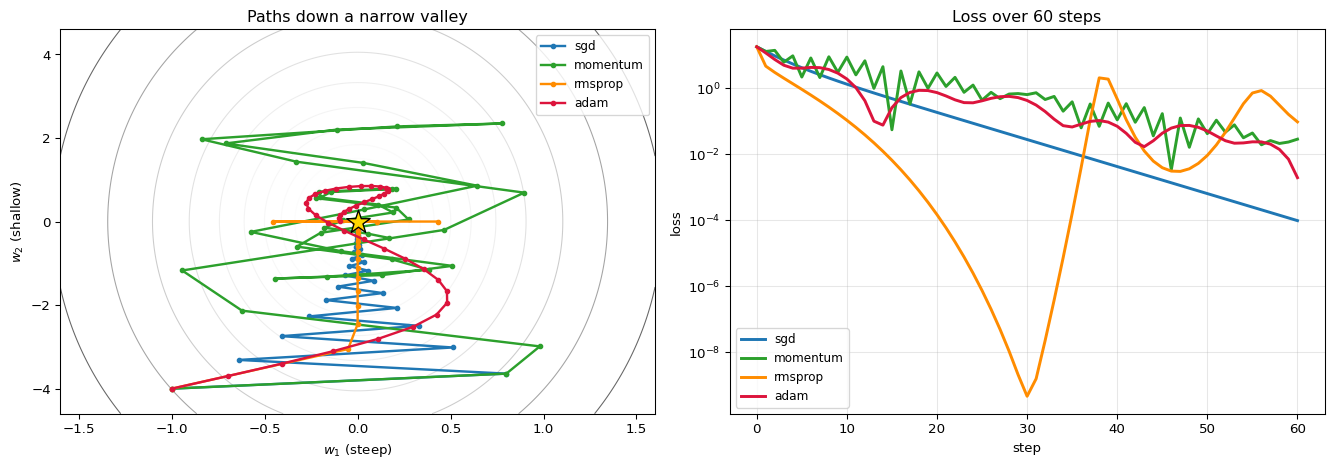

SGD zig-zags across the valley. Momentum damps the zig-zag and picks up
speed along it. RMSProp instead rescales each axis so the valley becomes
round. Adam does both, which is why it is the default.


In [6]:
def run(kind, steps=60, eta=None):
    w_ = W_START.copy(); path = [w_.copy()]
    m_ = np.zeros(2); v_ = np.zeros(2); s_ = np.zeros(2)
    for t in range(1, steps+1):
        g_ = grad(w_)
        if kind == "sgd":
            w_ = w_ - (eta or 0.09)*g_
        elif kind == "momentum":
            m_ = BETA*m_ + g_
            w_ = w_ - (eta or 0.09)*m_
        elif kind == "rmsprop":
            s_ = RHO*s_ + (1-RHO)*g_**2
            w_ = w_ - (eta or 0.3)*g_/(np.sqrt(s_)+EPS)
        else:
            m_ = B1*m_ + (1-B1)*g_
            v_ = B2*v_ + (1-B2)*g_**2
            mh, vh = m_/(1-B1**t), v_/(1-B2**t)
            w_ = w_ - (eta or 0.3)*mh/(np.sqrt(vh)+EPS_A)
        path.append(w_.copy())
    return np.array(path)

paths = {k: run(k) for k in ("sgd", "momentum", "rmsprop", "adam")}

print(f"{'optimiser':>12}  " + "  ".join(f"{'loss@'+str(s):>13}" for s in (5, 10, 25, 60)))
print("-" * 72)
for k, p in paths.items():
    print(f"{k:>12}  " + "  ".join(f"{loss(p[s]):>13.3e}" for s in (5, 10, 25, 60)))
print("-" * 72)

print(f"\nsteps needed to reach loss < 1e-4:\n")
for k, p in paths.items():
    hit = next((i for i in range(len(p)) if loss(p[i]) < 1e-4), None)
    print(f"   {k:>10}: {hit if hit is not None else '> 60'}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
g1v, g2v = np.meshgrid(np.linspace(-1.6, 1.6, 300), np.linspace(-4.6, 4.6, 300))
Lg = 0.5*(A_CURV*g1v**2 + B_CURV*g2v**2)
ax = axes[0]
ax.contour(g1v, g2v, Lg, levels=np.logspace(-2, 1.6, 22), cmap="Greys", linewidths=.8)
for k, col in [("sgd","tab:blue"), ("momentum","tab:green"),
               ("rmsprop","darkorange"), ("adam","crimson")]:
    p = paths[k][:40]
    ax.plot(p[:,0], p[:,1], "-o", lw=1.8, ms=3.2, color=col, label=k)
ax.scatter([0],[0], marker="*", s=340, c="gold", edgecolor="k", zorder=6)
ax.set(xlabel="$w_1$ (steep)", ylabel="$w_2$ (shallow)",
       title="Paths down a narrow valley")
ax.legend(fontsize=9)

ax = axes[1]
for k, col in [("sgd","tab:blue"), ("momentum","tab:green"),
               ("rmsprop","darkorange"), ("adam","crimson")]:
    ax.plot([loss(p) for p in paths[k]], lw=2.2, color=col, label=k)
ax.set(yscale="log", xlabel="step", ylabel="loss", title="Loss over 60 steps")
ax.legend(fontsize=9); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("SGD zig-zags across the valley. Momentum damps the zig-zag and picks up")
print("speed along it. RMSProp instead rescales each axis so the valley becomes")
print("round. Adam does both, which is why it is the default.")

### A surface with a local dip

The valley showed *scale*. This one shows the other thing momentum buys: enough inertia
to roll through a small local minimum that would trap plain descent.

   optimiser    final w1    final loss                     outcome
------------------------------------------------------------------
         sgd     -2.5702     -0.261535        STUCK in a local dip
    momentum     -2.5701     -0.263547        STUCK in a local dip
        adam     -2.5702     -0.263547        STUCK in a local dip
------------------------------------------------------------------


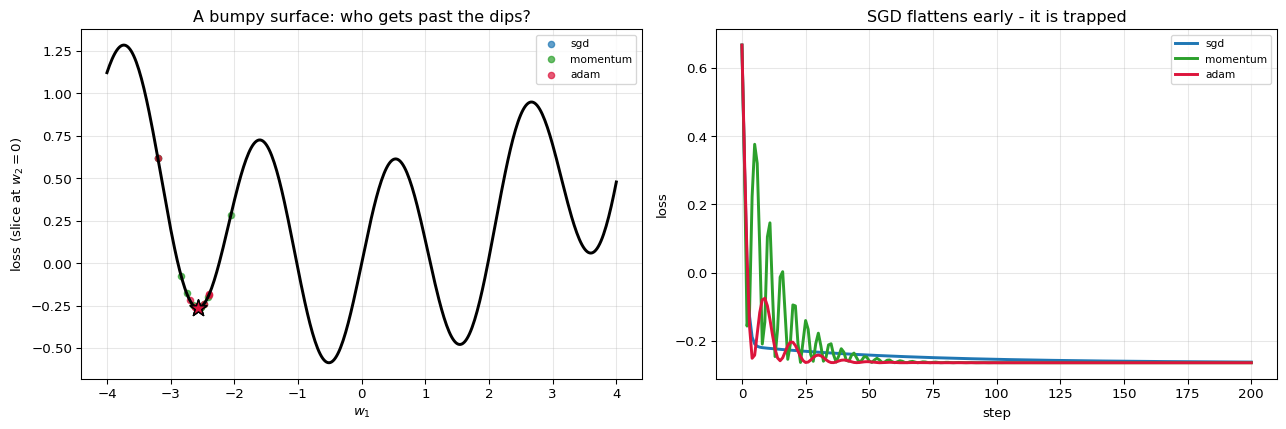

SGD stops at the first dip it meets, because the gradient there is zero
and it has no memory. Momentum arrives carrying velocity and rolls
through. This is the intuition behind 'momentum escapes local minima' -
though on real high-dimensional surfaces the more important effect is
simply that it damps oscillation and accelerates consistent directions.


In [7]:
def loss2(w):
    return 0.05*w[0]**2 + np.sin(3*w[0])*0.6 + 0.05*w[1]**2

def grad2(w):
    return np.array([0.1*w[0] + 1.8*np.cos(3*w[0]), 0.1*w[1]])

def run2(kind, steps=200, eta=0.08, start=np.array([-3.2, 1.0])):
    w_ = start.copy(); path=[w_.copy()]
    m_=np.zeros(2); v_=np.zeros(2)
    for t in range(1, steps+1):
        g_ = grad2(w_)
        if kind == "sgd":
            w_ = w_ - eta*g_
        elif kind == "momentum":
            m_ = 0.92*m_ + g_
            w_ = w_ - eta*m_
        else:
            m_ = B1*m_ + (1-B1)*g_
            v_ = B2*v_ + (1-B2)*g_**2
            w_ = w_ - 0.15*(m_/(1-B1**t))/(np.sqrt(v_/(1-B2**t))+EPS_A)
        path.append(w_.copy())
    return np.array(path)

xs = np.linspace(-4, 4, 400)
print(f"{'optimiser':>12}  {'final w1':>10}  {'final loss':>12}  {'outcome':>26}")
print("-" * 66)
res = {}
for k in ("sgd", "momentum", "adam"):
    p = run2(k); res[k] = p
    fin = p[-1]
    glob = xs[int(np.argmin([loss2(np.array([xx, 0.0])) for xx in xs]))]
    out = "reached the global basin" if abs(fin[0]-glob) < 0.8 else "STUCK in a local dip"
    print(f"{k:>12}  {fin[0]:>10.4f}  {loss2(fin):>12.6f}  {out:>26}")
print("-" * 66)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.6))
ax = axes[0]
ax.plot(xs, [loss2(np.array([xx, 0.0])) for xx in xs], lw=2.2, color="k")
for k, col in [("sgd","tab:blue"), ("momentum","tab:green"), ("adam","crimson")]:
    p = res[k]
    ax.scatter(p[::6,0], [loss2(np.array([q[0], 0.0])) for q in p[::6]],
               s=22, color=col, alpha=.7, label=k)
    ax.scatter([p[-1,0]], [loss2(np.array([p[-1,0],0.0]))], s=170, color=col,
               edgecolor="k", zorder=6, marker="*")
ax.set(xlabel="$w_1$", ylabel="loss (slice at $w_2=0$)",
       title="A bumpy surface: who gets past the dips?")
ax.legend(fontsize=8); ax.grid(alpha=.3)

ax = axes[1]
for k, col in [("sgd","tab:blue"), ("momentum","tab:green"), ("adam","crimson")]:
    ax.plot([loss2(q) for q in res[k]], lw=2.2, color=col, label=k)
ax.set(xlabel="step", ylabel="loss", title="SGD flattens early - it is trapped")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

print("SGD stops at the first dip it meets, because the gradient there is zero")
print("and it has no memory. Momentum arrives carrying velocity and rolls")
print("through. This is the intuition behind 'momentum escapes local minima' -")
print("though on real high-dimensional surfaces the more important effect is")
print("simply that it damps oscillation and accelerates consistent directions.")

---
# 6. Checking Against PyTorch

Adam has enough moving parts that an off-by-one in the bias correction is easy and
silent. The check: run our implementation and `torch.optim.Adam` from identical starting
points and compare the parameter trajectories step by step.

In [8]:
import torch

torch.set_default_dtype(torch.float64)

def torch_run(opt_name, steps=25, **kw):
    p = torch.tensor(W_START.copy(), requires_grad=True)
    opts = {
        "sgd": lambda: torch.optim.SGD([p], lr=kw.get("lr", 0.09)),
        "momentum": lambda: torch.optim.SGD([p], lr=kw.get("lr", 0.09),
                                            momentum=BETA),
        "rmsprop": lambda: torch.optim.RMSprop([p], lr=kw.get("lr", 0.3),
                                               alpha=RHO, eps=EPS),
        "adam": lambda: torch.optim.Adam([p], lr=kw.get("lr", 0.3),
                                         betas=(B1, B2), eps=EPS_A),
    }
    o = opts[opt_name]()
    traj = [p.detach().numpy().copy()]
    for _ in range(steps):
        o.zero_grad()
        l = 0.5*(A_CURV*p[0]**2 + B_CURV*p[1]**2)
        l.backward()
        o.step()
        traj.append(p.detach().numpy().copy())
    return np.array(traj)

print(f"{'optimiser':>12}  {'our final w':>26}  {'torch final w':>26}  {'match':>7}")
print("-" * 78)
for k in ("sgd", "momentum", "rmsprop", "adam"):
    ours = run(k, steps=25)
    theirs = torch_run(k, steps=25)
    ok = np.allclose(ours, theirs, atol=1e-9)
    print(f"{k:>12}  {str(np.round(ours[-1], 8)):>26}  "
          f"{str(np.round(theirs[-1], 8)):>26}  {str(ok):>7}")
print("-" * 78)

print(f"\n\nAdam trajectory, step by step\n")
ours_a = run("adam", steps=8)
th_a = torch_run("adam", steps=8)
print(f"{'step':>5}  {'ours w1':>13}  {'torch w1':>13}  {'ours w2':>13}  {'torch w2':>13}")
print("-" * 66)
for k in range(9):
    print(f"{k:>5}  {ours_a[k,0]:>13.9f}  {th_a[k,0]:>13.9f}  "
          f"{ours_a[k,1]:>13.9f}  {th_a[k,1]:>13.9f}")
print("-" * 66)
print(f"\nfull-trajectory MATCH: {np.allclose(ours_a, th_a, atol=1e-10)}")
print(f"max difference: {np.abs(ours_a - th_a).max():.3e}")

print(f"\n\nnote on torch's momentum convention:")
print(f"   ours  : v = beta*v + g   then  w -= eta*v")
print(f"   torch : identical (this is 'heavy ball', not Nesterov)")
print(f"   trajectories agree: {np.allclose(run('momentum', 25), torch_run('momentum', 25), atol=1e-9)}")
print(f"\nSome papers instead write v = beta*v + (1-beta)*g, which rescales the")
print(f"effective learning rate by (1-beta). Both appear in the literature, so")
print(f"a learning rate is only meaningful alongside its momentum convention.")

   optimiser                 our final w               torch final w    match
------------------------------------------------------------------------------
         sgd           [ 0.0038 -0.3785]           [ 0.0038 -0.3785]     True
    momentum           [-0.1994 -0.2708]           [-0.1994 -0.2708]     True
     rmsprop           [ 0.     -0.0012]           [ 0.     -0.0012]     True
        adam             [0.0737 0.8511]             [0.0737 0.8511]     True
------------------------------------------------------------------------------


Adam trajectory, step by step

 step        ours w1       torch w1        ours w2       torch w2
------------------------------------------------------------------
    0   -1.000000000   -1.000000000   -4.000000000   -4.000000000
    1   -0.700000000   -0.700000000   -3.700000001   -3.700000001
    2   -0.407283850   -0.407283850   -3.400836323   -3.400836323
    3   -0.131961645   -0.131961645   -3.103172802   -3.103172802
    4    0.110193129  

---
# 7. Practical Notes

**Adam is not always better.** For image classification, well-tuned SGD with momentum
often *generalises* better than Adam, even though Adam reaches a lower training loss
faster. The adaptive step sizes appear to favour sharper minima. Adam's real strength is
that it works acceptably with almost no tuning, which matters when you cannot afford a
learning-rate search.

**AdamW fixes weight decay.** Adding $\lambda\lVert w\rVert^2$ to the loss is *not*
equivalent to shrinking $w$ each step once the update is divided by $\sqrt{\hat{v}}$ &mdash;
the decay gets scaled by the adaptive term too. AdamW applies the decay separately, and
is the correct default for Transformers.

**Learning-rate schedules still matter.** Adaptive step sizes are not a schedule; warmup
and cosine decay remain standard.

In [9]:
print("effective step size Adam takes, regardless of gradient magnitude\n")
print(f"{'gradient':>12}  {'m_hat':>12}  {'sqrt(v_hat)':>13}  "
      f"{'m_hat/sqrt(v_hat)':>19}")
print("-" * 62)
for gv in (1e-4, 1e-2, 1.0, 100.0, 10000.0):
    m_, v_ = 0.0, 0.0
    for t in range(1, 40):
        m_ = B1*m_ + (1-B1)*gv
        v_ = B2*v_ + (1-B2)*gv**2
    mh, vh = m_/(1-B1**39), v_/(1-B2**39)
    print(f"{gv:>12.0e}  {mh:>12.4e}  {np.sqrt(vh):>13.4e}  {mh/np.sqrt(vh):>19.6f}")
print("-" * 62)
print("\nFor a CONSTANT gradient the ratio is 1 whatever its size - so Adam's step")
print("is about eta, regardless of scale. That is the property that makes it")
print("robust to badly scaled problems, and also why its eta means something")
print("different from SGD's (1e-3 is a typical Adam default, vs 1e-1 for SGD).\n")

print(f"{'optimiser':>12}  {'typical eta':>13}  {'needs tuning?':>15}  {'common use':>28}")
print("-" * 74)
for nm, lr, tune, use in [
        ("SGD", "1e-2 - 1e-1", "a lot", "when you can tune, vision"),
        ("Momentum", "1e-2 - 1e-1", "a lot", "SGD's default companion"),
        ("RMSProp", "1e-3", "some", "RNNs, older code"),
        ("Adam", "1e-3", "little", "almost everything"),
        ("AdamW", "1e-3", "little", "Transformers")]:
    print(f"{nm:>12}  {lr:>13}  {tune:>15}  {use:>28}")
print("-" * 74)

effective step size Adam takes, regardless of gradient magnitude

    gradient         m_hat    sqrt(v_hat)    m_hat/sqrt(v_hat)
--------------------------------------------------------------
       1e-04    1.0000e-04     1.0000e-04             1.000000
       1e-02    1.0000e-02     1.0000e-02             1.000000
       1e+00    1.0000e+00     1.0000e+00             1.000000
       1e+02    1.0000e+02     1.0000e+02             1.000000
       1e+04    1.0000e+04     1.0000e+04             1.000000
--------------------------------------------------------------

For a CONSTANT gradient the ratio is 1 whatever its size - so Adam's step
is about eta, regardless of scale. That is the property that makes it
robust to badly scaled problems, and also why its eta means something
different from SGD's (1e-3 is a typical Adam default, vs 1e-1 for SGD).

   optimiser    typical eta    needs tuning?                    common use
-------------------------------------------------------------------

---
# 8. Summary

| Optimiser | Update |
|---|---|
| SGD | $w \leftarrow w - \eta g$ |
| Momentum | $v \leftarrow \beta v + g$; $\;w \leftarrow w - \eta v$ |
| RMSProp | $s \leftarrow \rho s + (1-\rho)g^2$; $\;w \leftarrow w - \frac{\eta}{\sqrt{s}+\epsilon}g$ |
| Adam | $m,v$ as above; $\hat m = \frac{m}{1-\beta_1^t}$, $\hat v = \frac{v}{1-\beta_2^t}$; $\;w \leftarrow w - \frac{\eta}{\sqrt{\hat v}+\epsilon}\hat m$ |

**The one idea:** the gradient tells you the direction. Everything after SGD is about
choosing the **step**, using information the raw gradient does not contain &mdash; its recent
history (momentum) and its typical magnitude per parameter (RMSProp).

**Why bias correction exists:** both moving averages start at zero, so early estimates are
biased toward zero. Dividing by $1-\beta^t$ removes exactly that bias, and at $t=1$
recovers the raw gradient. It is three characters of code and easy to omit, and omitting
it makes the first few hundred steps wrong.

**What is deliberately left out:** Nesterov momentum, AdaGrad (RMSProp's ancestor, whose
denominator grows without bound so the rate decays to zero), AdaDelta, LAMB and LARS for
very large batches, second-order methods (L-BFGS, K-FAC), and learning-rate schedules,
which are a separate lever from the optimiser.